In [49]:
import pandas as pd
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

In [4]:
from ucimlrepo import fetch_ucirepo

superconductivity_data = fetch_ucirepo(id=464)

X = superconductivity_data.data.features
y = superconductivity_data.data.targets

df = pd.concat([X,y], axis = 1)

print(df.head())


   number_of_elements  mean_atomic_mass  wtd_mean_atomic_mass  \
0                   4         88.944468             57.862692   
1                   5         92.729214             58.518416   
2                   4         88.944468             57.885242   
3                   4         88.944468             57.873967   
4                   4         88.944468             57.840143   

   gmean_atomic_mass  wtd_gmean_atomic_mass  entropy_atomic_mass  \
0          66.361592              36.116612             1.181795   
1          73.132787              36.396602             1.449309   
2          66.361592              36.122509             1.181795   
3          66.361592              36.119560             1.181795   
4          66.361592              36.110716             1.181795   

   wtd_entropy_atomic_mass  range_atomic_mass  wtd_range_atomic_mass  \
0                 1.062396          122.90607              31.794921   
1                 1.057755          122.90607           

In [25]:
X = df.drop(columns = ['critical_temp'])
y = df['critical_temp']

In [43]:
labeled_pool, unlabelled_pool = train_test_split(df, train_size=250, random_state=42)


In [47]:

X_labeled = labeled_pool.drop(columns=['critical_temp'])
y_labeled = labeled_pool['critical_temp']

X_train, X_test, y_train, y_test = train_test_split(
    X_labeled, y_labeled, test_size=0.2, random_state=42
)

X_unlabelled = unlabelled_pool.drop(columns=['critical_temp'])
y_unlabelled = unlabelled_pool['critical_temp']

# --- 2. INITIALIZE & COLD START ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_unlabelled_scaled = scaler.transform(X_unlabelled)

kernel = Matern(nu=2.5, length_scale=1.0, length_scale_bounds=(1e-2, 1e4))
GP = GaussianProcessRegressor(kernel=kernel, alpha=1e-2, normalize_y=True, random_state=42, n_restarts_optimizer=2)

GP.fit(X_train_scaled, y_train)

validation_errors = []
# --- 3. Active learning
n_iterations = 10
kappa = 1.96

print("🧪 Initiating Active Learning Discovery Loop\n" + "="*60)

for i in range(n_iterations):
    # Predict over the pool
    mu_pool, std_pool = GP.predict(X_unlabelled_scaled, return_std=True)

    # Calculate UCB and locate best candidate
    ucb_scores = mu_pool + (kappa * std_pool)
    best_local_idx = np.argmax(ucb_scores)

    # Convert NumPy index back to Pandas index
    best_global_idx = X_unlabelled.index[best_local_idx]

    # Oracle query
    true_temp = y_unlabelled.loc[best_global_idx]
    pred_temp = mu_pool[best_local_idx]
    uncertainty = std_pool[best_local_idx]


    # Mutate State
    candidate_features = X_unlabelled.loc[[best_global_idx]]
    candidate_target = y_unlabelled.loc[[best_global_idx]]

    X_train = pd.concat([X_train, candidate_features])
    y_train = pd.concat([y_train, candidate_target])

    X_unlabelled = X_unlabelled.drop(index=best_global_idx)
    y_unlabelled = y_unlabelled.drop(index=best_global_idx)

    # Re-scale and re-fit
    X_train_scaled = scaler.fit_transform(X_train)
    X_unlabelled_scaled = scaler.transform(X_unlabelled)
    GP.fit(X_train_scaled, y_train)

    #Evaluation measure
    X_test_scaled_current = scaler.transform(X_test)
    test_preds = GP.predict(X_test_scaled_current)
    current_mae = mean_absolute_error(y_test, test_preds)
    validation_errors.append(current_mae)

    print(f"Iteration {i+1} | Material Index: {best_global_idx}")
    print(f"Model Predicted : {pred_temp:>6.2f} K (± {uncertainty:.2f})")
    print(f" Oracle Result   : {true_temp:>6.2f} K")
    print(f"Validation set MAE : {current_mae:>6.2f} k")
    print("-" * 60)

print(f"\n✅ Loop Complete. Final Training Set Size: {X_train.shape[0]} materials.")

🧪 Initiating Active Learning Discovery Loop
Iteration 1 | Material Index: 7770
Model Predicted : 100.44 K (± 21.55)
 Oracle Result   :  92.00 K
Validation set MAE :  26.11 k
------------------------------------------------------------
Iteration 2 | Material Index: 7780
Model Predicted : 117.01 K (± 10.70)
 Oracle Result   :  98.00 K
Validation set MAE :  26.49 k
------------------------------------------------------------
Iteration 3 | Material Index: 2192
Model Predicted :  95.99 K (± 21.80)
 Oracle Result   : 114.00 K
Validation set MAE :  26.57 k
------------------------------------------------------------
Iteration 4 | Material Index: 1686
Model Predicted :  70.57 K (± 30.49)
 Oracle Result   : 114.70 K
Validation set MAE :  26.65 k
------------------------------------------------------------
Iteration 5 | Material Index: 1341
Model Predicted :  85.18 K (± 28.43)
 Oracle Result   : 136.00 K
Validation set MAE :  26.79 k
------------------------------------------------------------
I

CAlculating permutance importances


/tmp/ipykernel_13212/2504819989.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(result.importances[sorted_idx].T, vert = False, tick_labels = X.columns[sorted_idx])


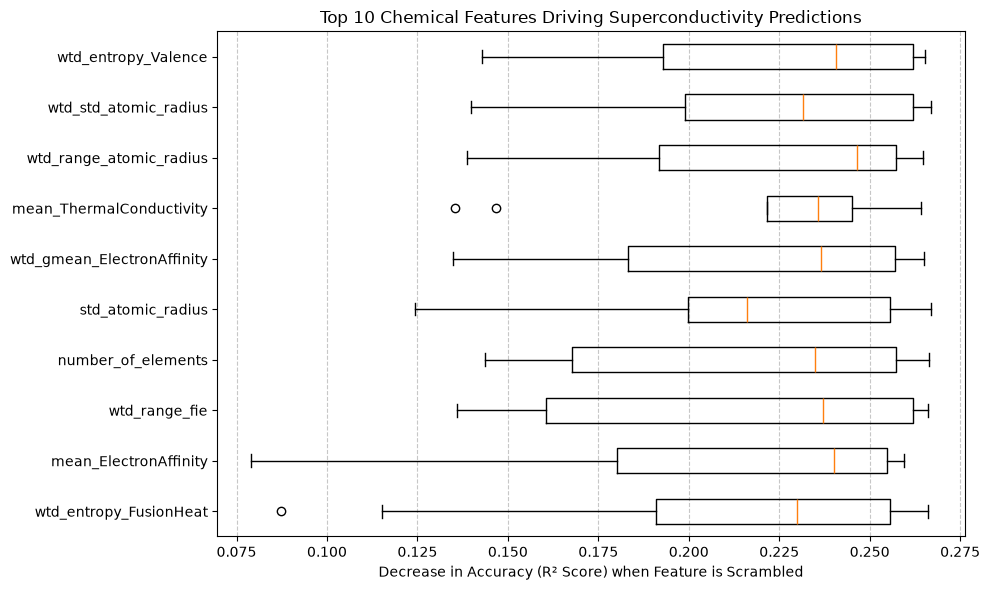

In [53]:
print("CAlculating permutance importances")
X_test_scaled_final = scaler.transform(X_test)

result = permutation_importance(GP, X_test_scaled_final, y_test, n_repeats = 10, random_state = 42, n_jobs = -1)

#Islolating top 10 critical features
sorted_idx = result.importances_mean.argsort()[-10:]

#Visualization
fig, ax = plt.subplots(figsize = (10,6))
ax.boxplot(result.importances[sorted_idx].T, vert = False, tick_labels = X.columns[sorted_idx])

ax.set_title("Top 10 Chemical Features Driving Superconductivity Predictions")
ax.set_xlabel("Decrease in Accuracy (R² Score) when Feature is Scrambled")
ax.grid(axis='x', linestyle='--', alpha=0.7)
fig.tight_layout()
plt.show()